# Comparing Experiments

## Import package

In [1]:
import os
import h5py
import numpy as np

from typing import cast
from pathlib import Path
from glob import glob

from matplotlib import pyplot as plt

style_path = Path("/home/b11209013/Kuang-python/v0.1.0_Analysis/scientific.mplstyle")

plt.style.use(style_path)

## Load data

Each NPZ entry is now a named numeric array. Load them into a dictionary per
experiment, so `composite_results["NoRad"]["J"]` accesses heating directly and
`composite_results["NoRad"]["z"]` accesses height. `composites` provides the
same variable-only access used below, excluding the coordinate arrays.


In [2]:
data_path: Path = Path("/home/b11209013/Kuang-python/v0.1.0_Analysis/output/v0.1.0")
files: list[Path] = sorted(data_path.glob("*.npz"))
if not files:
    raise FileNotFoundError(f"No composite NPZ files found in {data_path}")

# Load named arrays while each archive is open; no object unpacking is needed.
composite_results: dict[str, dict[str, np.ndarray]] = {}
for file in files:
    with np.load(file, allow_pickle=False) as archive:
        composite_results[file.stem] = {name: archive[name] for name in archive.files}

# Keep the variable-only mapping for comparisons, separate from coordinates.
coordinate_names = {"x", "z", "time", "x_relative"}
composites = {
    exp: {name: values for name, values in result.items() if name not in coordinate_names}
    for exp, result in composite_results.items()
}
print("Loaded experiments:", ", ".join(composite_results))


Loaded experiments: NoRad, Rad


## Compare Quantities

In [3]:
for exp, result in composite_results.items():
    print(f"{exp}: {result['x'].size} x points, {result['z'].size} levels, "
          f"{result['time'].size} composite times")
    print("Available arrays:", list(result))
    print("Composite fields:", {name: values.shape for name, values in composites[exp].items()})


NoRad: 401 x points, 71 levels, 20 composite times
Available arrays: ['w1', 'w2', 'T1', 'T2', 'J1', 'J2', 'N2', 'N2_anom', 'conv_gen', 'J', 'w', 'T', 'x', 'z', 'time', 'x_relative']
Composite fields: {'w1': (401, 71), 'w2': (401, 71), 'T1': (401, 71), 'T2': (401, 71), 'J1': (401, 71), 'J2': (401, 71), 'N2': (401, 71), 'N2_anom': (401, 71), 'conv_gen': (401, 71), 'J': (401, 71), 'w': (401, 71), 'T': (401, 71)}
Rad: 401 x points, 71 levels, 20 composite times
Available arrays: ['w1', 'w2', 'T1', 'T2', 'J1', 'J2', 'N2', 'N2_anom', 'conv_gen', 'J', 'w', 'T', 'x', 'z', 'time', 'x_relative']
Composite fields: {'w1': (401, 71), 'w2': (401, 71), 'T1': (401, 71), 'T2': (401, 71), 'J1': (401, 71), 'J2': (401, 71), 'N2': (401, 71), 'N2_anom': (401, 71), 'conv_gen': (401, 71), 'J': (401, 71), 'w': (401, 71), 'T': (401, 71)}


## NoRad shading and Rad contours

Start with `conv_gen`, the heating–temperature product plotted in the composite
notebook. Edit `comparison_variables` to compare other saved fields. Each figure
shows NoRad shading and labeled Rad contours over −30° to 30° on the left.
Dotted vertical lines mark the averaging region, −10° to 10°. The right panel
compares each experiment's arithmetic longitude mean at every height within
that inclusive interval; NaNs are ignored.

Use each experiment's own spatial grid. Rad contour levels are chosen from its
own range and labeled in the same physical units as the shading. Both mean
profiles share the same value axis, so amplitude differences remain visible.
Negative contour values are dashed; positive values are solid.

In [4]:
display_longitude_bounds = (-30.0, 30.0)
mean_longitude_bounds = (-10.0, 10.0)
comparison_figure_dir = Path(
    "/home/b11209013/Kuang-python/v0.1.0_Analysis/Figure/experiment_comparison"
)
os.makedirs(comparison_figure_dir, exist_ok=True)

# Fields to compare as name -> (title, units); units follow the composite notebook.
comparison_variables = {
    "conv_gen": (r"$J^\prime T^\prime$", "K$^2$/day"),
    "J": ("$J$", "K/day"),
    "J1": ("$J_1$", "K/day"),
    "J2": ("$J_2$", "K/day"),
    "T": ("$T$", "K"),
    "T1": ("$T_1$", "K"),
    "T2": ("$T_2$", "K"),
    "w": ("$w$", "m/day"),
    "w1": ("$w_1$", "m/day"),
    "w2": ("$w_2$", "m/day"),
    "N2": ("$N^2$", "s$^{-2}$"),
    "N2_anom": ("$N^{2\\prime}$", "s$^{-2}$"),
}

# Exports are written to experiment_comparison/<style name>/.
export_styles = ("slides", "manuscript")
# Style shown inline during the export loop.
plot_style = "slides"
manuscript_width_mm = 180.0
manuscript_height_mm = 115.0
mm_per_inch = 25.4

figure_styles = {
    "slides": {
        "figsize": (16.0, 9.0),  # 1920 x 1080 px at 120 dpi
        "dpi": 120,
        "formats": ("png",),
        "rc": {
            "font.size": 20,
            "axes.titlesize": 24,
            "axes.labelsize": 22,
            "xtick.labelsize": 18,
            "ytick.labelsize": 18,
            "legend.fontsize": 18,
            "lines.linewidth": 3.0,
        },
    },
    "manuscript": {
        "figsize": (manuscript_width_mm / mm_per_inch, manuscript_height_mm / mm_per_inch),
        "dpi": 300,
        "formats": ("png",),
        "rc": {
            "font.size": 8,
            "axes.titlesize": 10,
            "axes.labelsize": 9,
            "xtick.labelsize": 8,
            "ytick.labelsize": 8,
            "legend.fontsize": 8,
            "lines.linewidth": 1.0,
            "axes.labelpad": 3,
        },
    },
}


## Slide and manuscript exports

Both versions use the same fields, colors, contour levels, and longitude means.
Slides use larger labels on a 16:9 canvas and export at **1920 × 1080 pixels**.
Manuscript figures use **180 × 115 mm** with 8–11 pt text at that physical size,
and export to PDF and 300 dpi PNG. Set `manuscript_width_mm` to your journal's
required width; the default is a two-column layout, not a journal specification.

Choose `plot_style` for the inline preview. The export loop writes both styles
under `experiment_comparison/slides/` and `experiment_comparison/manuscript/`.
Typography is local to each figure. Titles are shortened, panels are labeled
(a)/(b), the mean-profile panel is wider, and fewer contour labels/colorbar ticks
leave room for larger text. Only alternate contour levels receive text labels;
all contour lines remain plotted. Exports retain their specified dimensions.


In [5]:
def plot_experiment_comparison(variable, label, units, display_bounds, mean_bounds, style_name):
    """Overlay the two spatial composites and compare their central means."""
    style = figure_styles[style_name]
    metres_per_degree = 2 * np.pi * 6.371e6 / 360.0
    plot_data = {}
    profiles = {}
    for experiment in ("NoRad", "Rad"):
        result = composite_results[experiment]
        longitude = result["x_relative"] / metres_per_degree
        height_km = result["z"] / 1000.0
        values = result[variable]
        if values.shape != (longitude.size, height_km.size):
            raise ValueError(f"{experiment}/{variable}: expected shape (x, z).")
        visible = (longitude >= display_bounds[0]) & (longitude <= display_bounds[1])
        mean_region = (longitude >= mean_bounds[0]) & (longitude <= mean_bounds[1])
        if visible.sum() < 2 or not np.any(mean_region):
            raise ValueError(f"{experiment}: insufficient longitude points for the requested domains.")
        limit = float(np.nanmax(np.abs(values[visible, :])))
        if not np.isfinite(limit):
            raise ValueError(f"{experiment}/{variable}: no finite values in the displayed domain.")
        plot_data[experiment] = (longitude, height_km, values, limit)
        profiles[experiment] = {
            "height_km": height_km,
            "mean": np.nanmean(values[mean_region, :], axis=0),
        }

    # Limit typography changes to this figure; keep the shared mplstyle intact.
    with plt.rc_context(rc=style["rc"]):
        fig = plt.figure(figsize=style["figsize"], layout="constrained")
        fig.suptitle(label, fontsize=plt.rcParams["axes.titlesize"])
        grid = fig.add_gridspec(2, 2, height_ratios=[1, 0.06], width_ratios=[2.6, 1.4])
        ax_structure = fig.add_subplot(grid[0, 0])
        ax_profile = fig.add_subplot(grid[0, 1], sharey=ax_structure)
        cax = fig.add_subplot(grid[1, 0])

        longitude, height_km, values, limit = plot_data["NoRad"]
        limit = limit or 1e-12
        shading = ax_structure.contourf(
            longitude, height_km, values.T,
            levels=np.linspace(-limit, limit, 21), cmap="RdBu_r", extend="both",
        )
        longitude, height_km, values, limit = plot_data["Rad"]
        if limit > 0:
            # Separate labeled contour levels reveal the weaker Rad structure.
            rad_visible = (longitude >= display_bounds[0]) & (longitude <= display_bounds[1])
            rad_min = float(np.nanmin(values[rad_visible, :]))
            rad_max = float(np.nanmax(values[rad_visible, :]))
            # Resolve both signs even when one has a much smaller amplitude.
            levels = np.array(
                ([rad_min * fraction for fraction in (0.75, 0.5, 0.25)] if rad_min < 0 else [])
                + ([rad_max * fraction for fraction in (0.25, 0.5, 0.75)] if rad_max > 0 else [])
            )
            contours = ax_structure.contour(
                longitude, height_km, values.T, levels=levels, colors="k", linewidths=plt.rcParams["lines.linewidth"],
                linestyles=["dashed" if level < 0 else "solid" for level in levels],
            )
            # Label alternate levels to leave room for larger text.
            ax_structure.clabel(contours, levels=levels[::2], fmt="%.1e",
                                fontsize=plt.rcParams["font.size"], inline=True)
        else:
            ax_structure.text(0.02, 0.03, "Rad is zero throughout the displayed region",
                              transform=ax_structure.transAxes, fontsize=plt.rcParams["font.size"])
        for boundary in mean_bounds:
            ax_structure.axvline(boundary, color="0.35", linestyle=":", linewidth=plt.rcParams["lines.linewidth"])
        ax_structure.set(
            xlabel="Relative longitude (°)", ylabel="Height (km)",
            xlim=display_bounds,
            ylim=(min(data[1].min() for data in plot_data.values()),
                  max(data[1].max() for data in plot_data.values())),
        )
        ax_structure.set_title("(a) NoRad shading; Rad contours", fontsize=plt.rcParams["axes.titlesize"])
        colorbar = fig.colorbar(shading, cax=cax, orientation="horizontal",
                               label=f"NoRad ({units})")
        colorbar.ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
        colorbar.ax.locator_params(axis="x", nbins=4)

        for experiment, color in (("NoRad", "tab:blue"), ("Rad", "k")):
            profile = profiles[experiment]
            ax_profile.plot(profile["mean"], profile["height_km"],
                            label=experiment, color=color, linewidth=plt.rcParams["lines.linewidth"])
        ax_profile.axvline(0.0, color="0.5", linestyle="--", linewidth=plt.rcParams["lines.linewidth"])
        ax_profile.set_title(f"(b) {mean_bounds[0]:g}° to {mean_bounds[1]:g}° mean", fontsize=plt.rcParams["axes.titlesize"])
        ax_profile.set_xlabel(f"Mean ({units})")
        ax_profile.tick_params(labelleft=False)
        ax_profile.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
        ax_profile.locator_params(axis="x", nbins=3)
        ax_profile.grid(alpha=0.25)
        ax_profile.legend()
        # Make the scientific-notation multipliers as readable as the ticks.
        for axis in (ax_structure.xaxis, ax_structure.yaxis, ax_profile.xaxis, colorbar.ax.xaxis):
            axis.get_offset_text().set_fontsize(style["rc"]["xtick.labelsize"])
        return fig, profiles

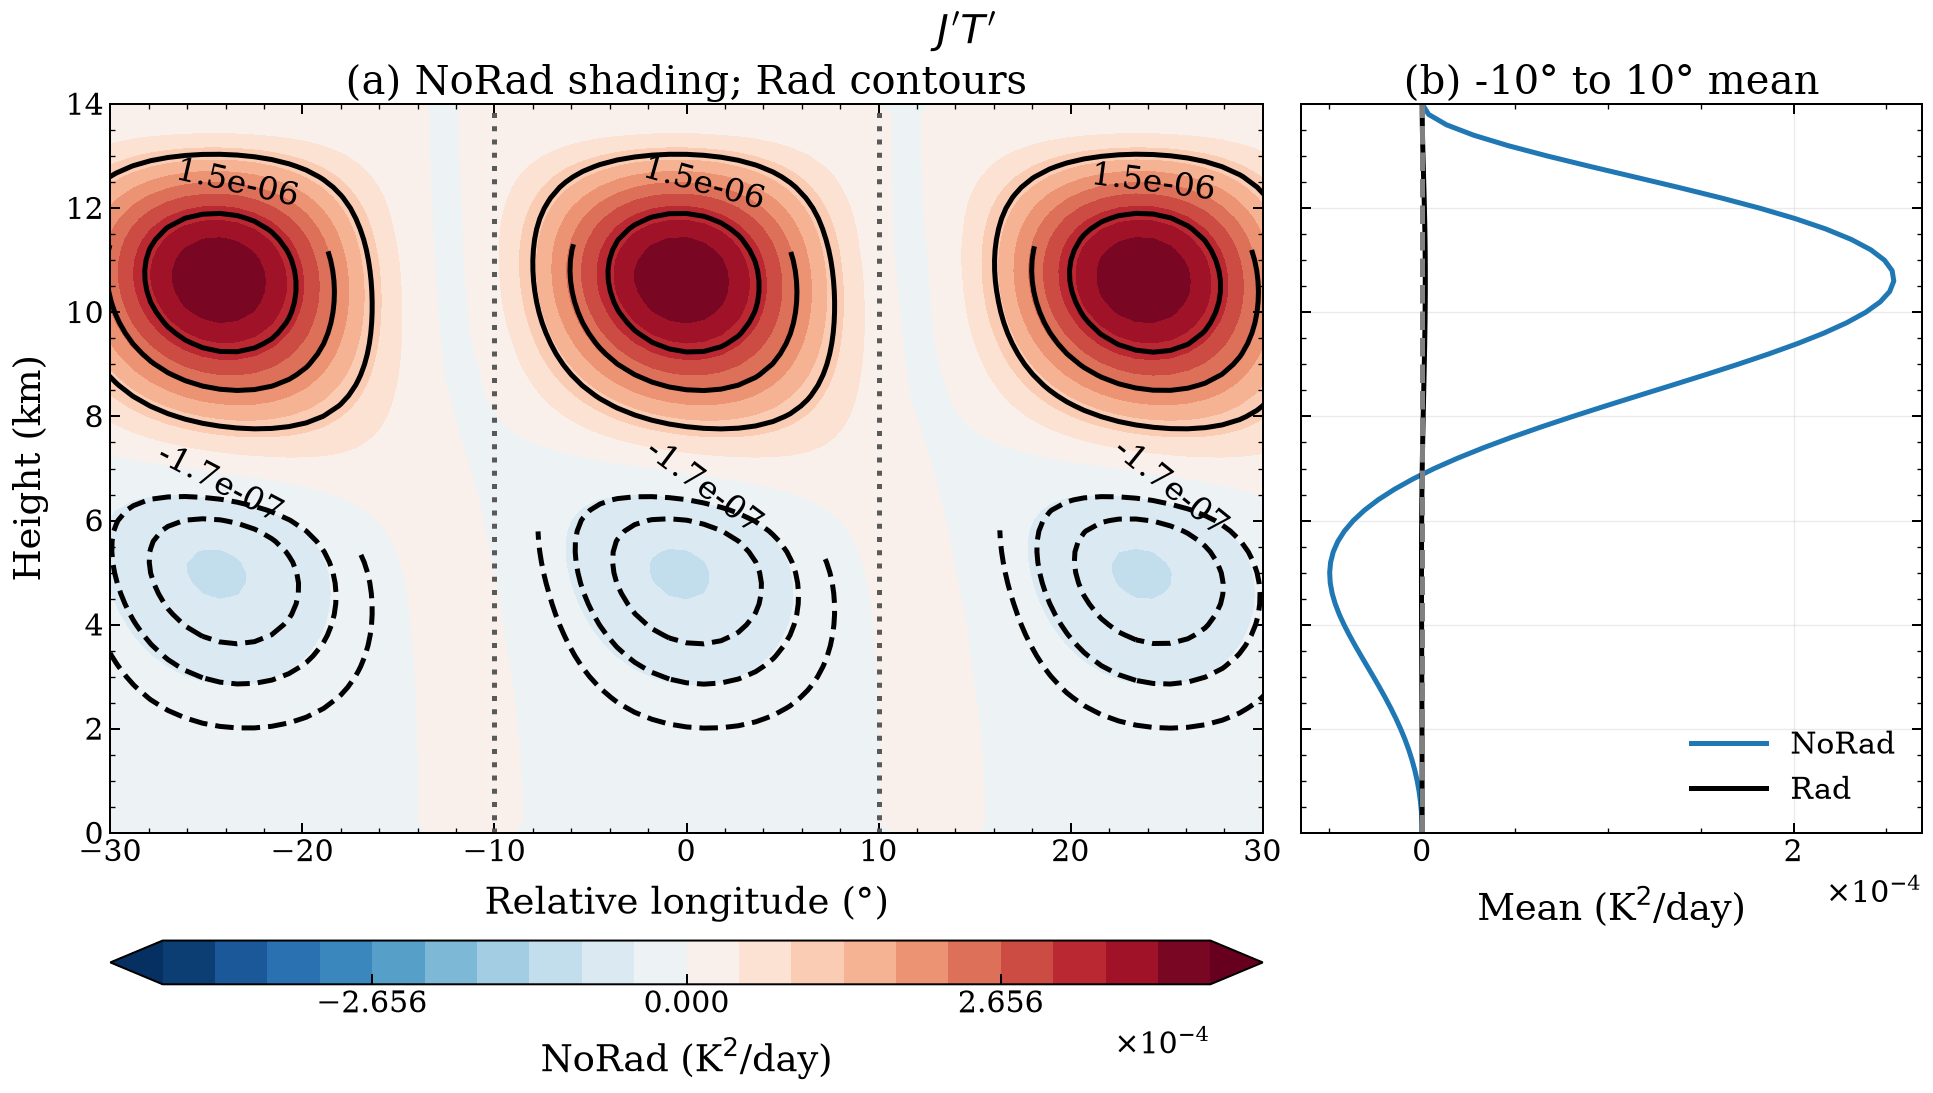

Saved conv_gen: slides, manuscript


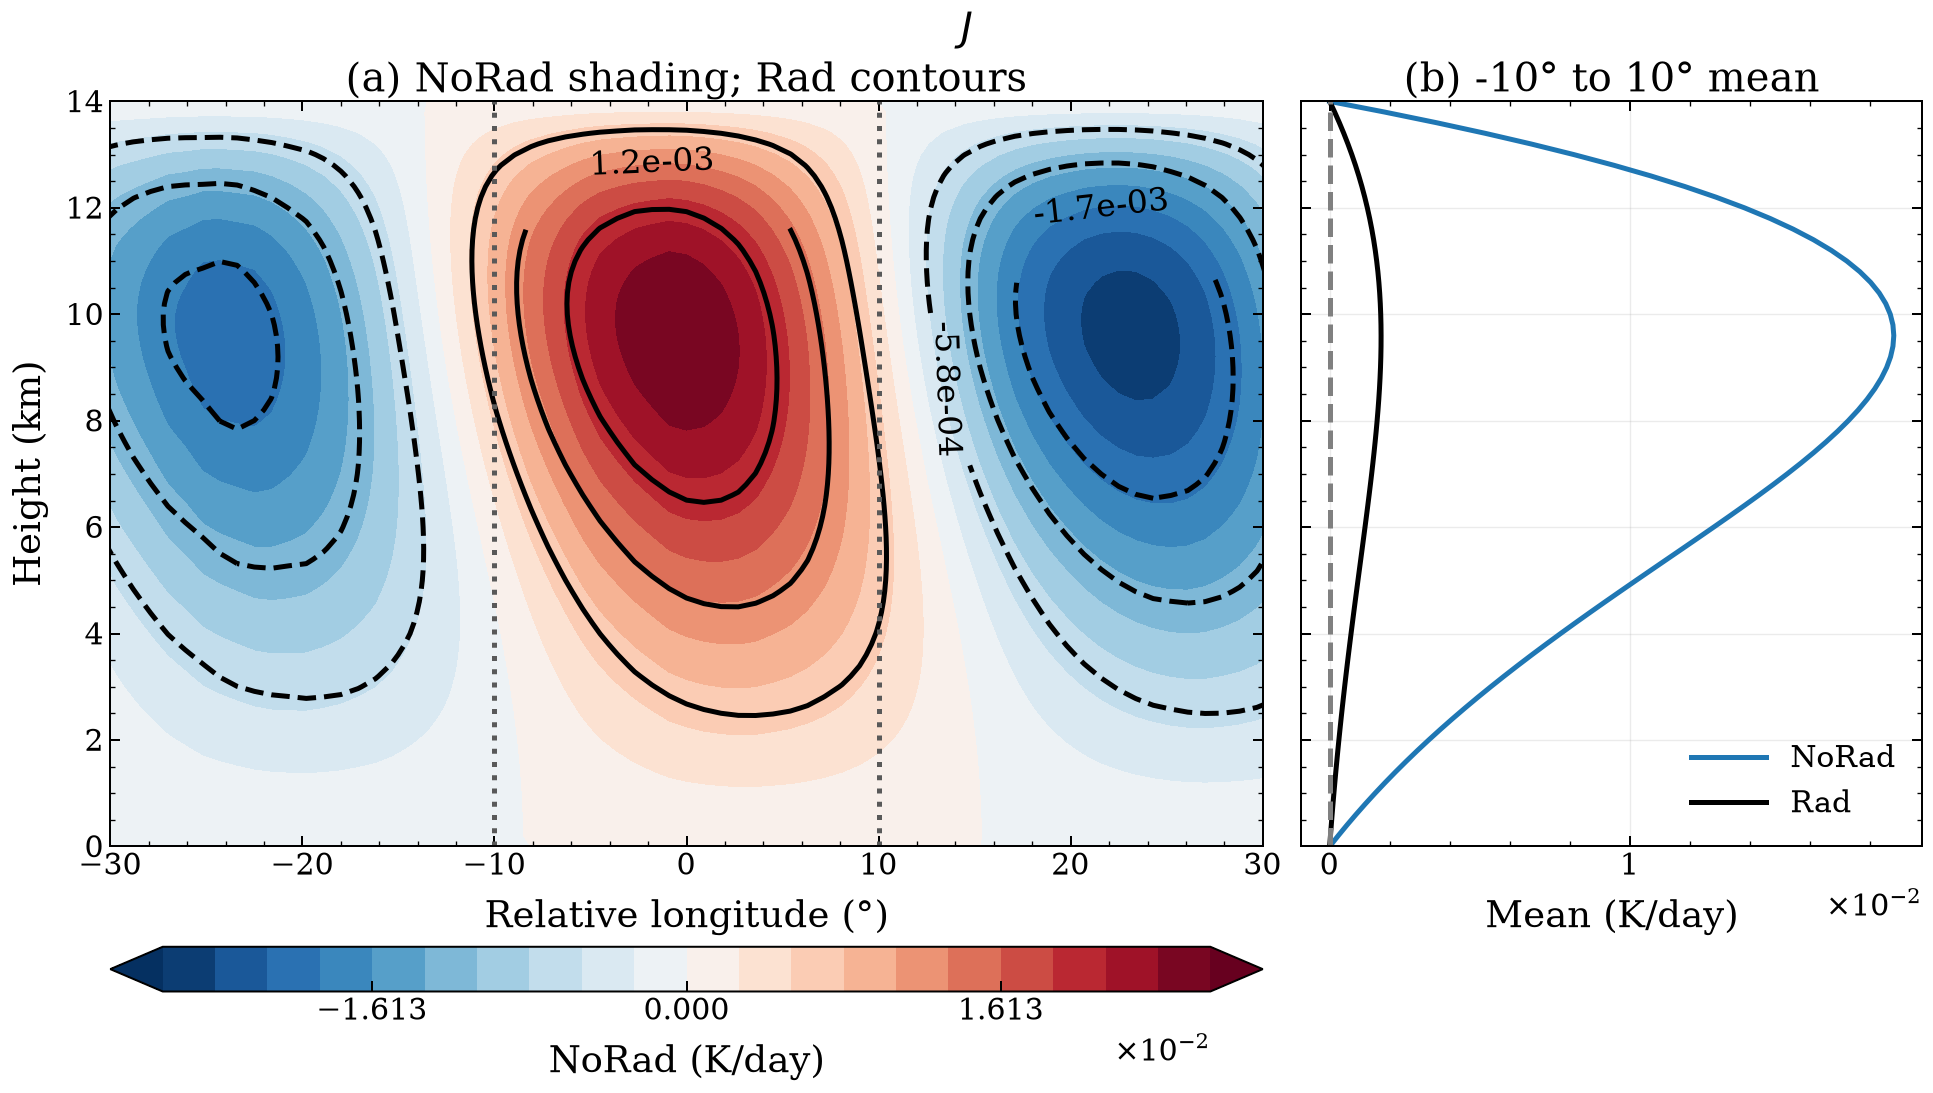

Saved J: slides, manuscript


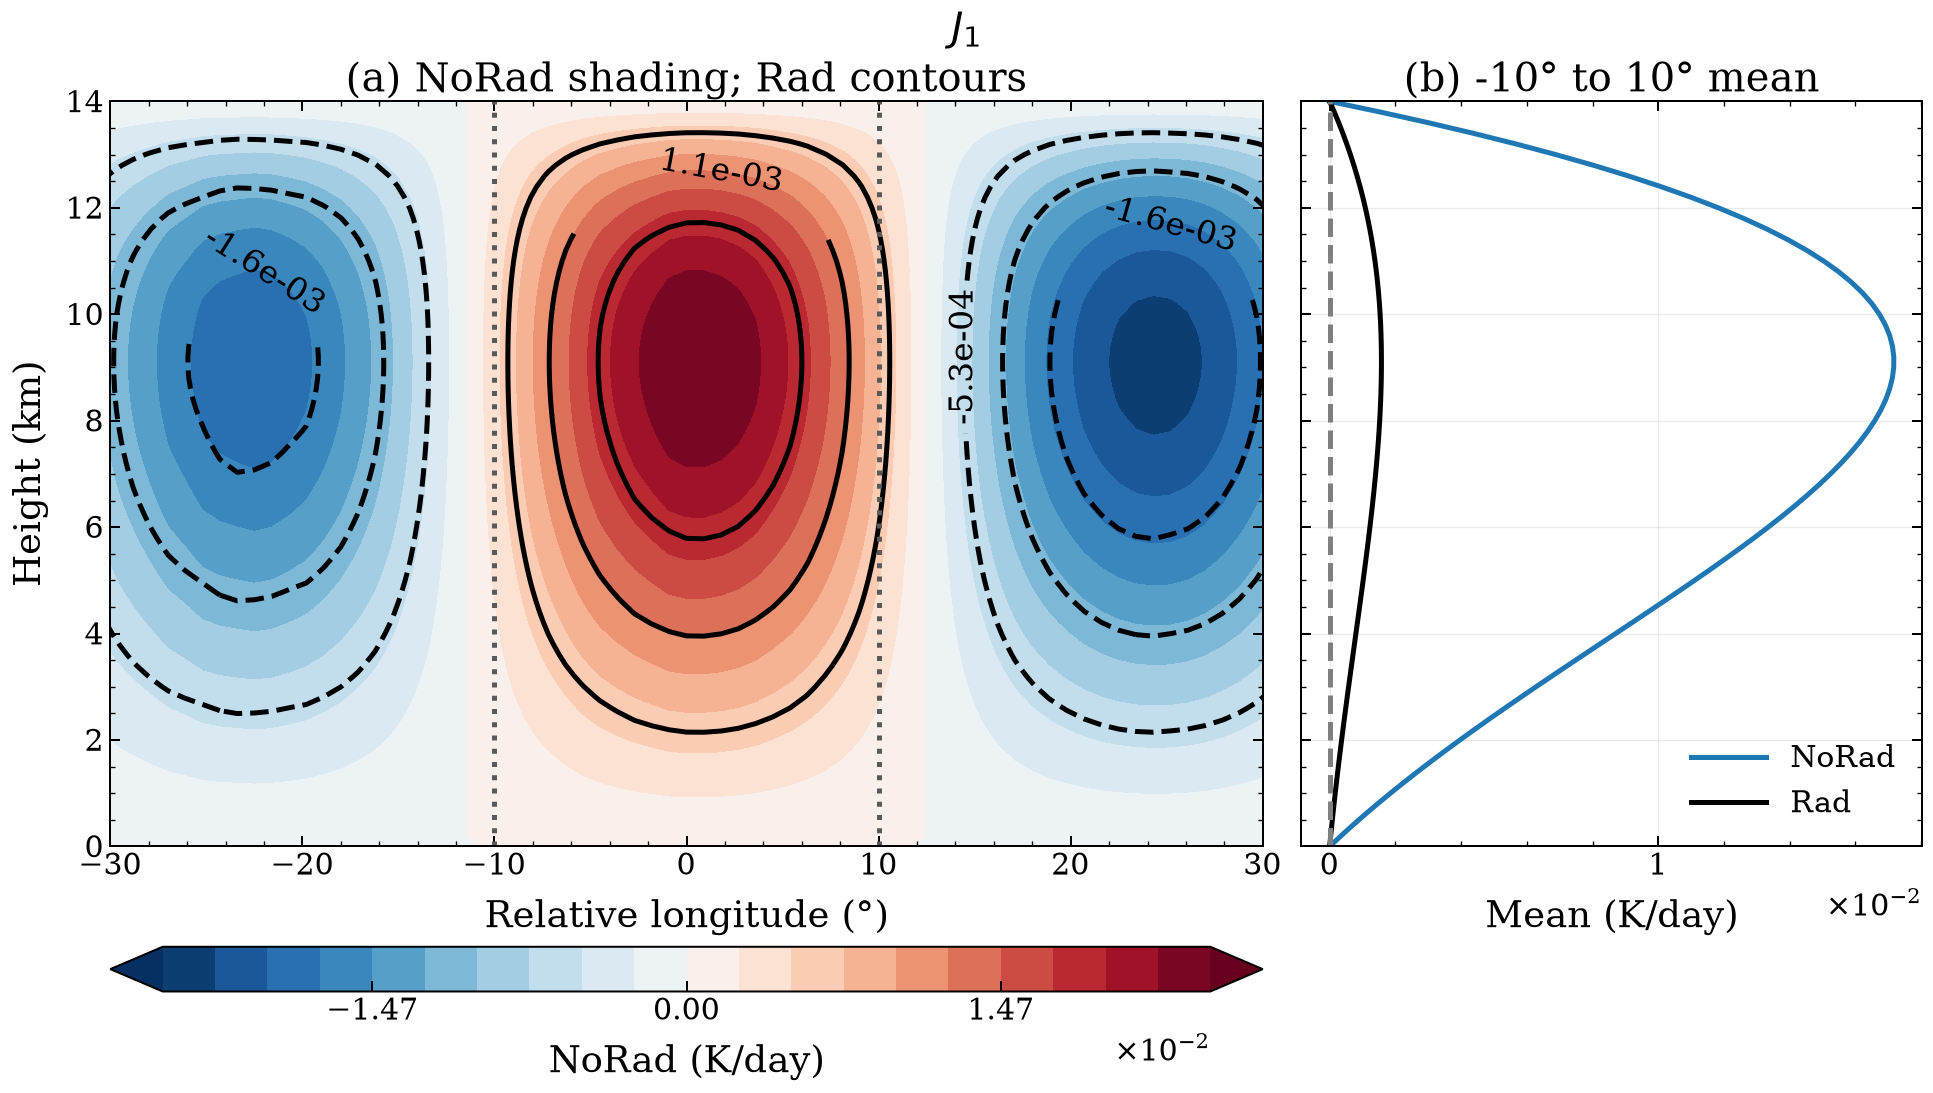

Saved J1: slides, manuscript


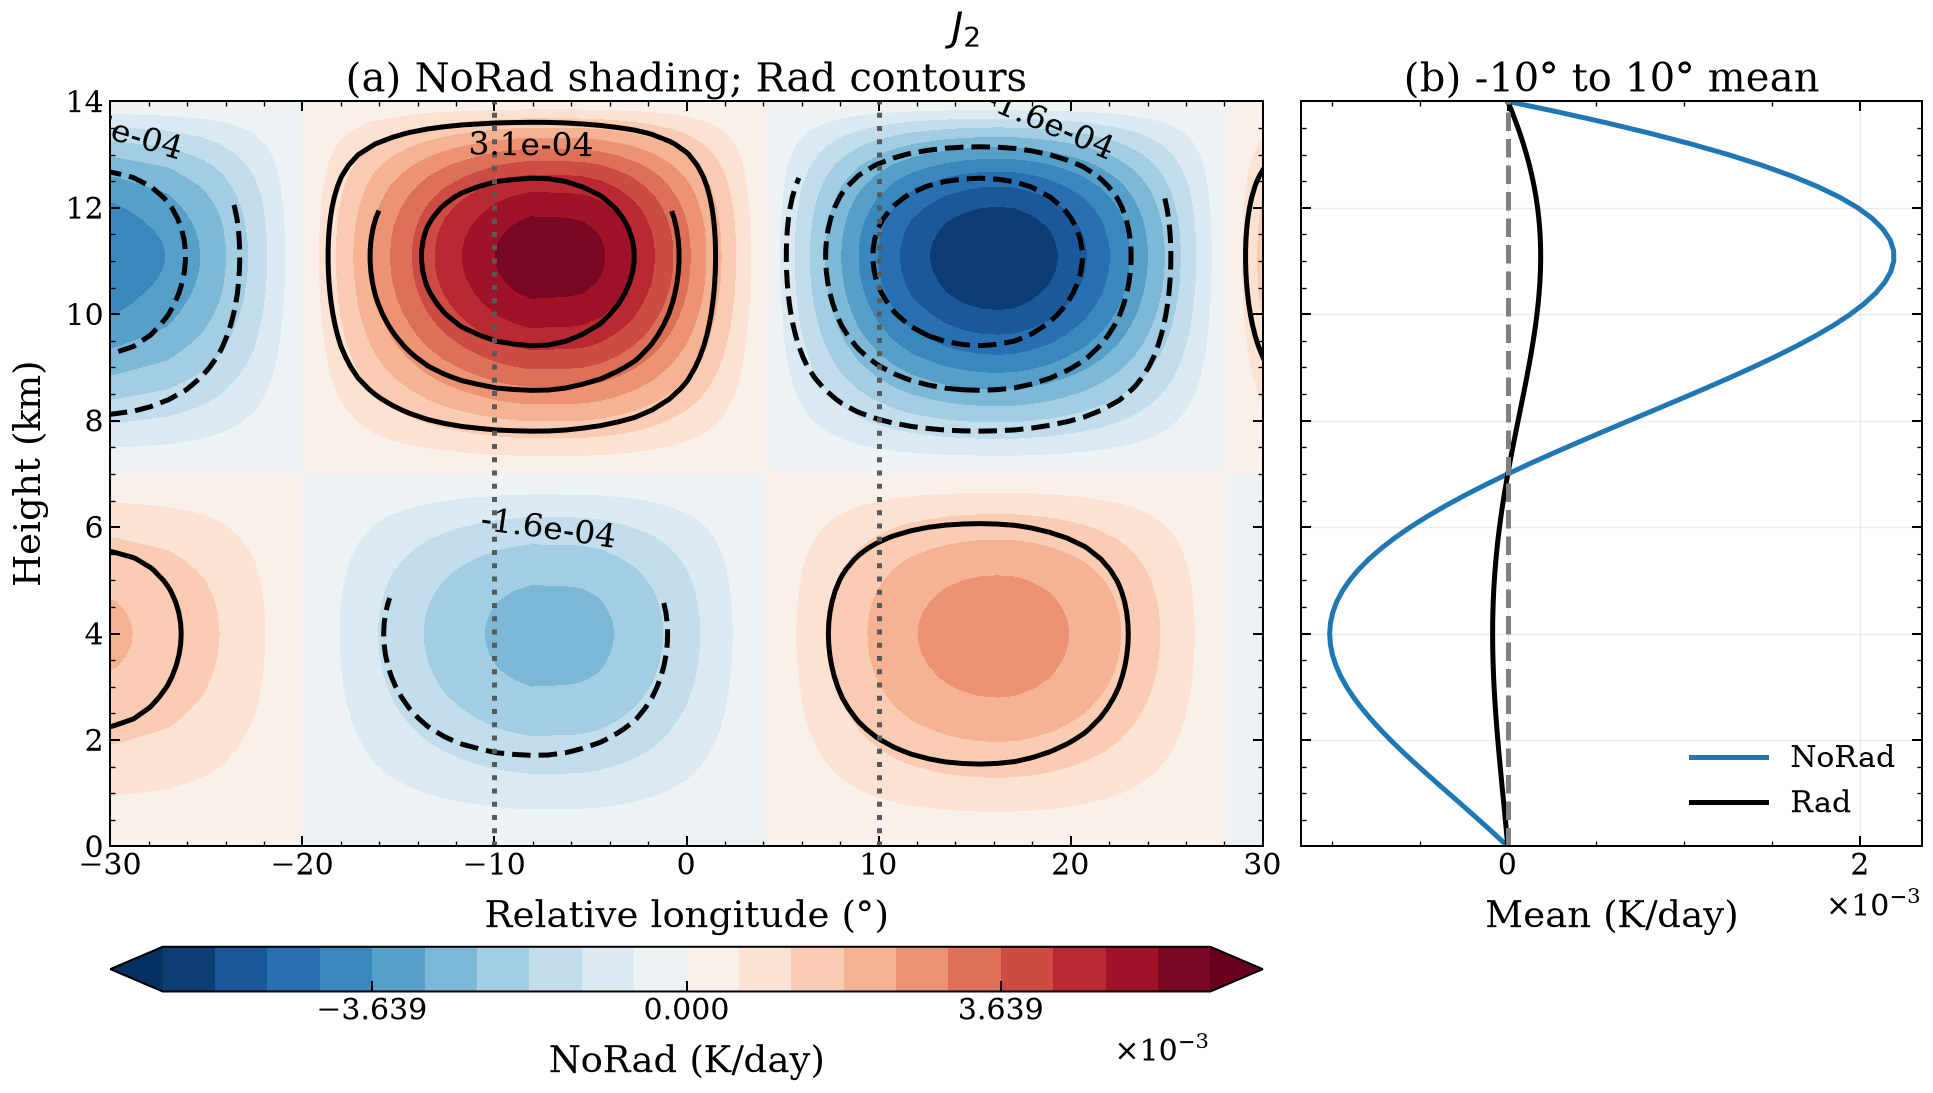

Saved J2: slides, manuscript


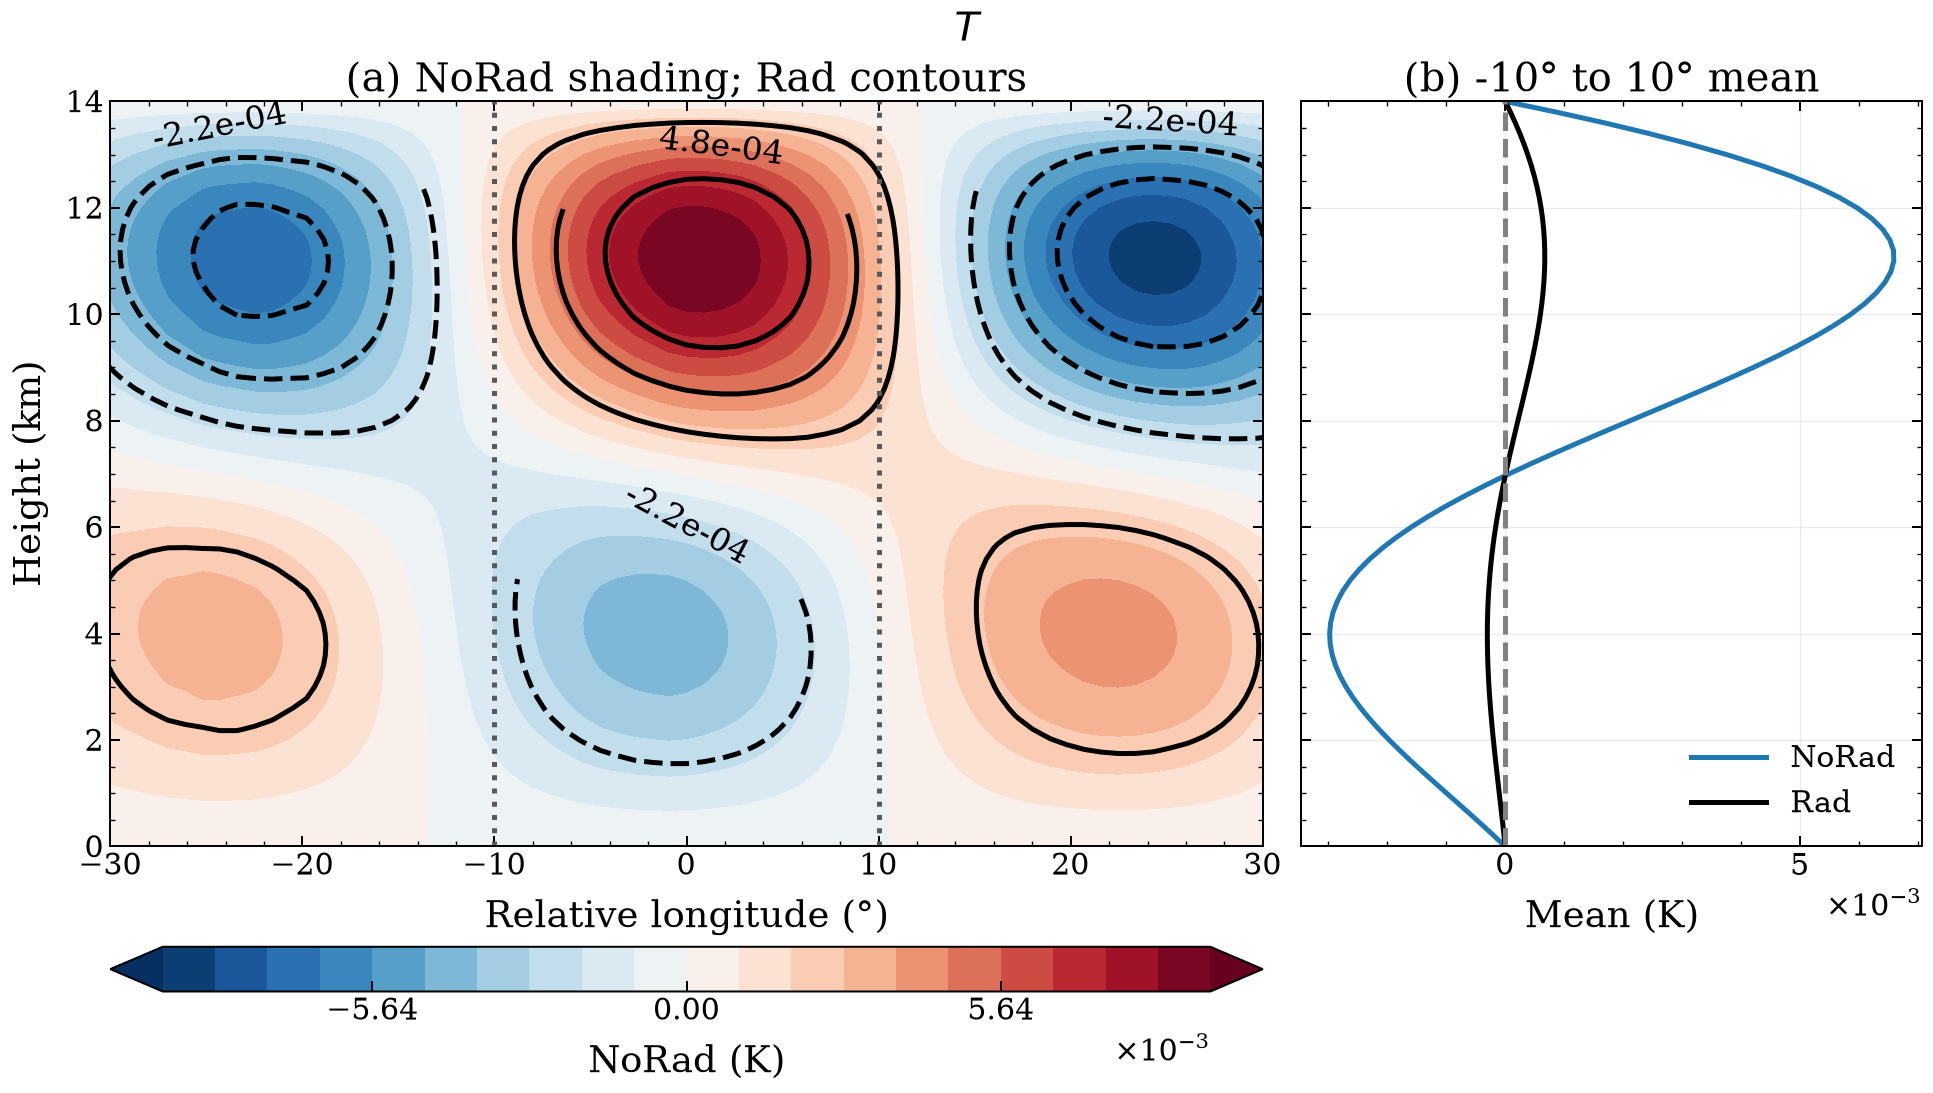

Saved T: slides, manuscript


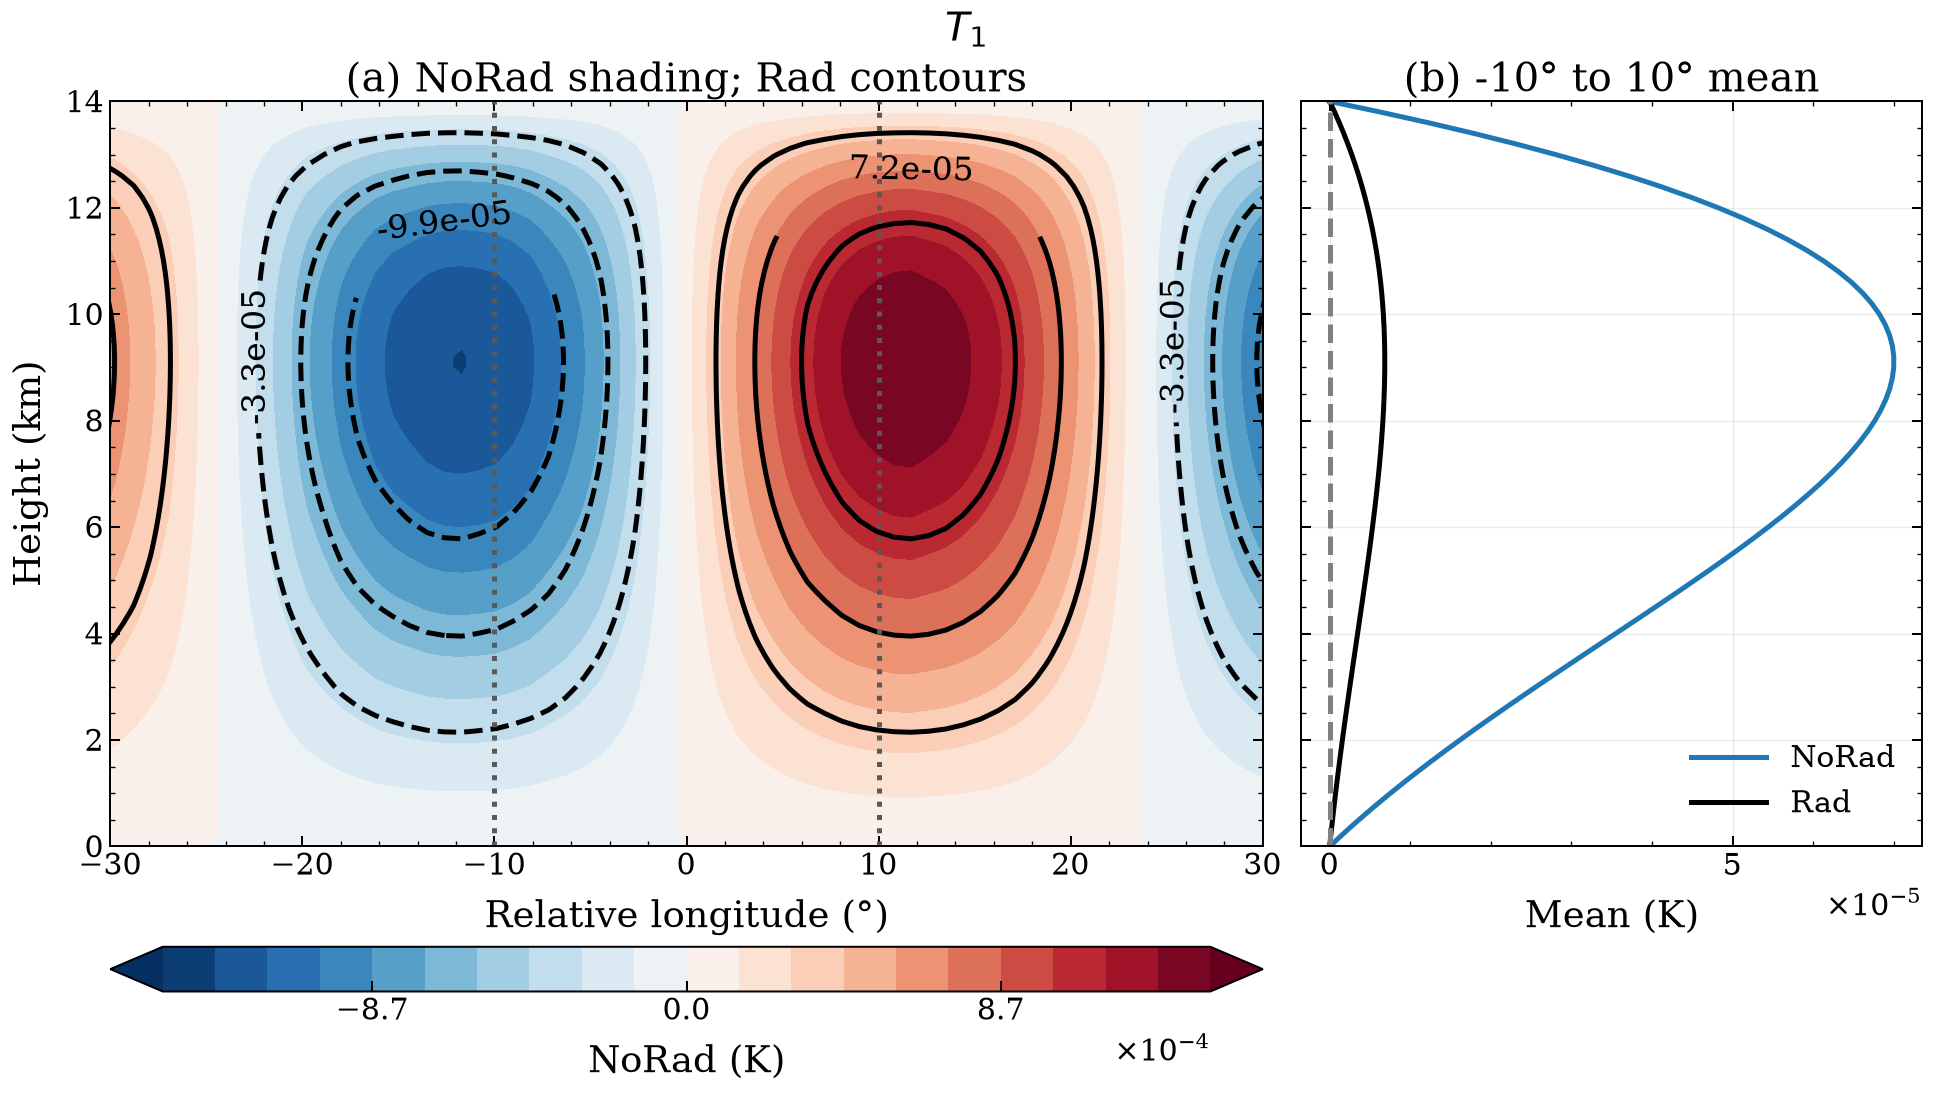

Saved T1: slides, manuscript


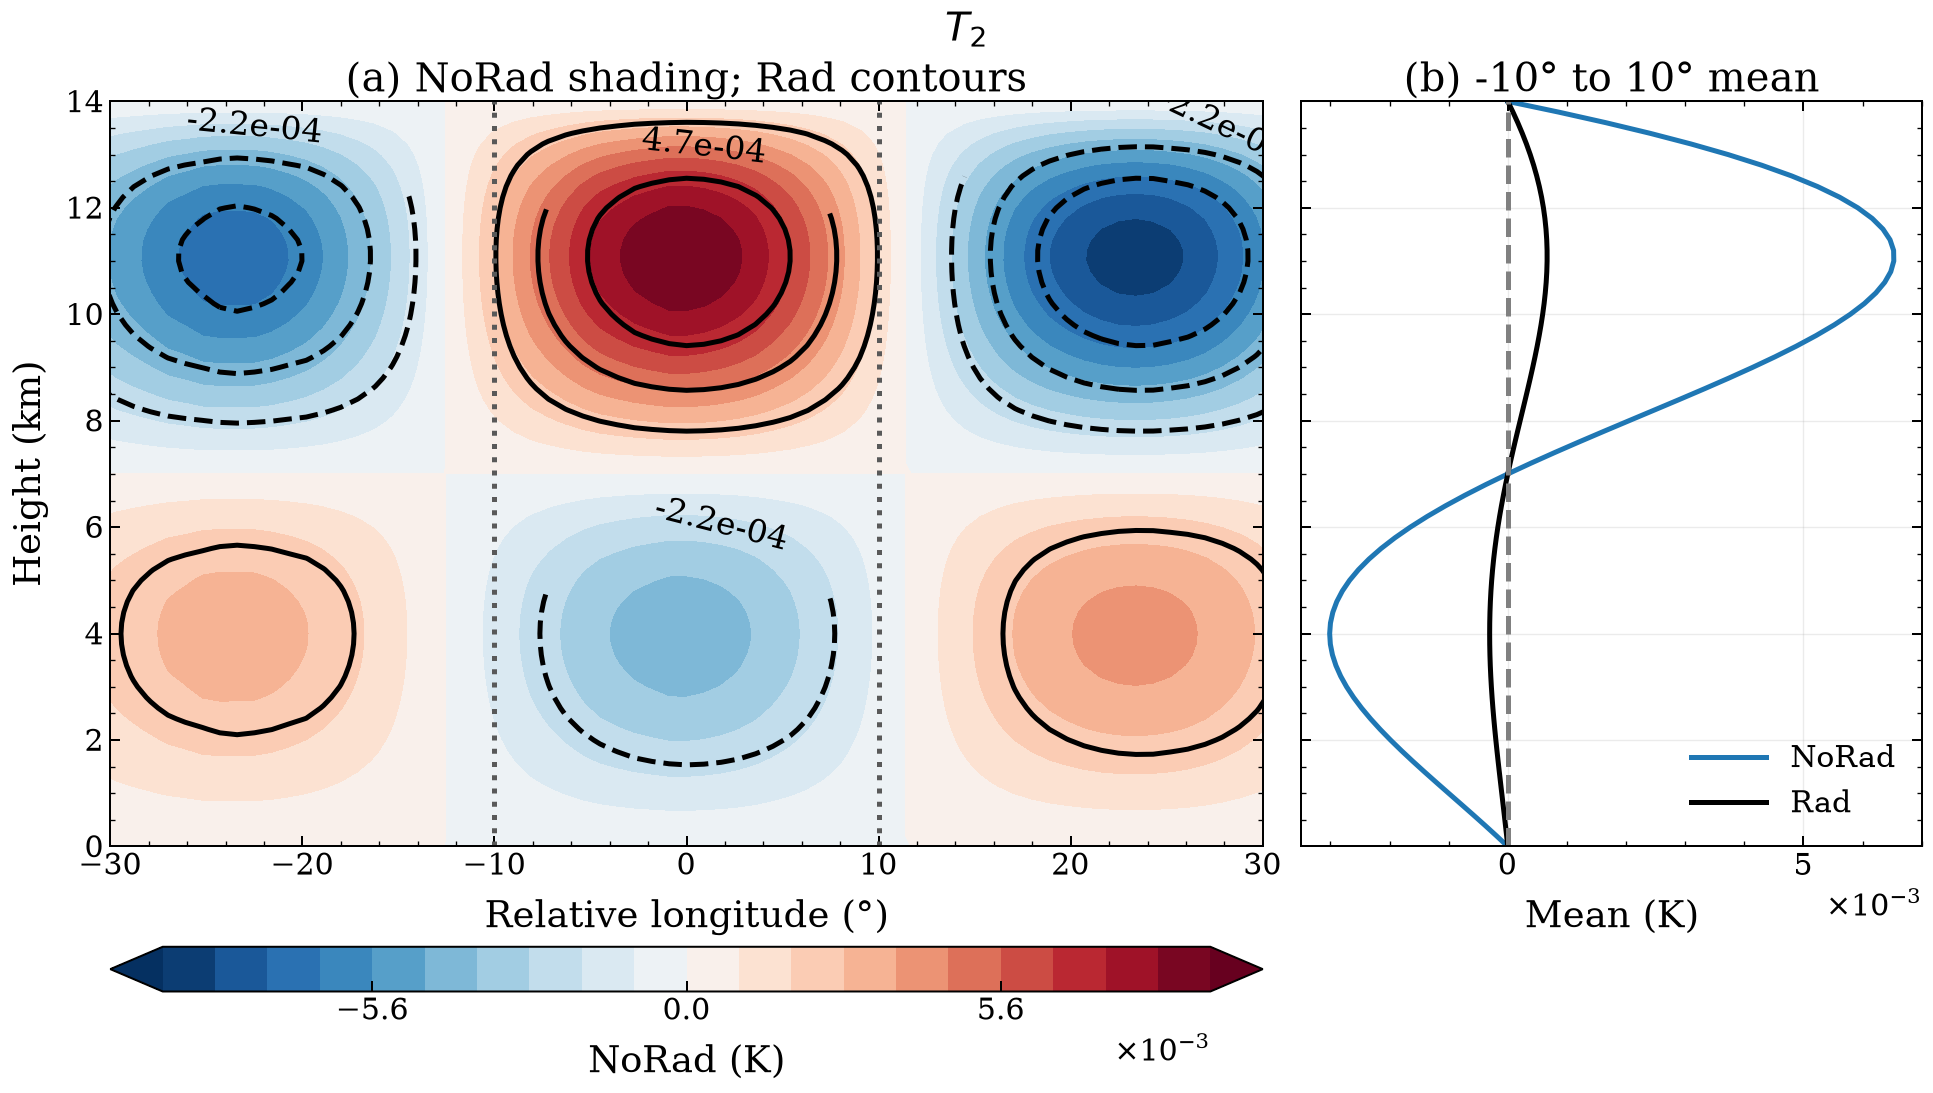

Saved T2: slides, manuscript


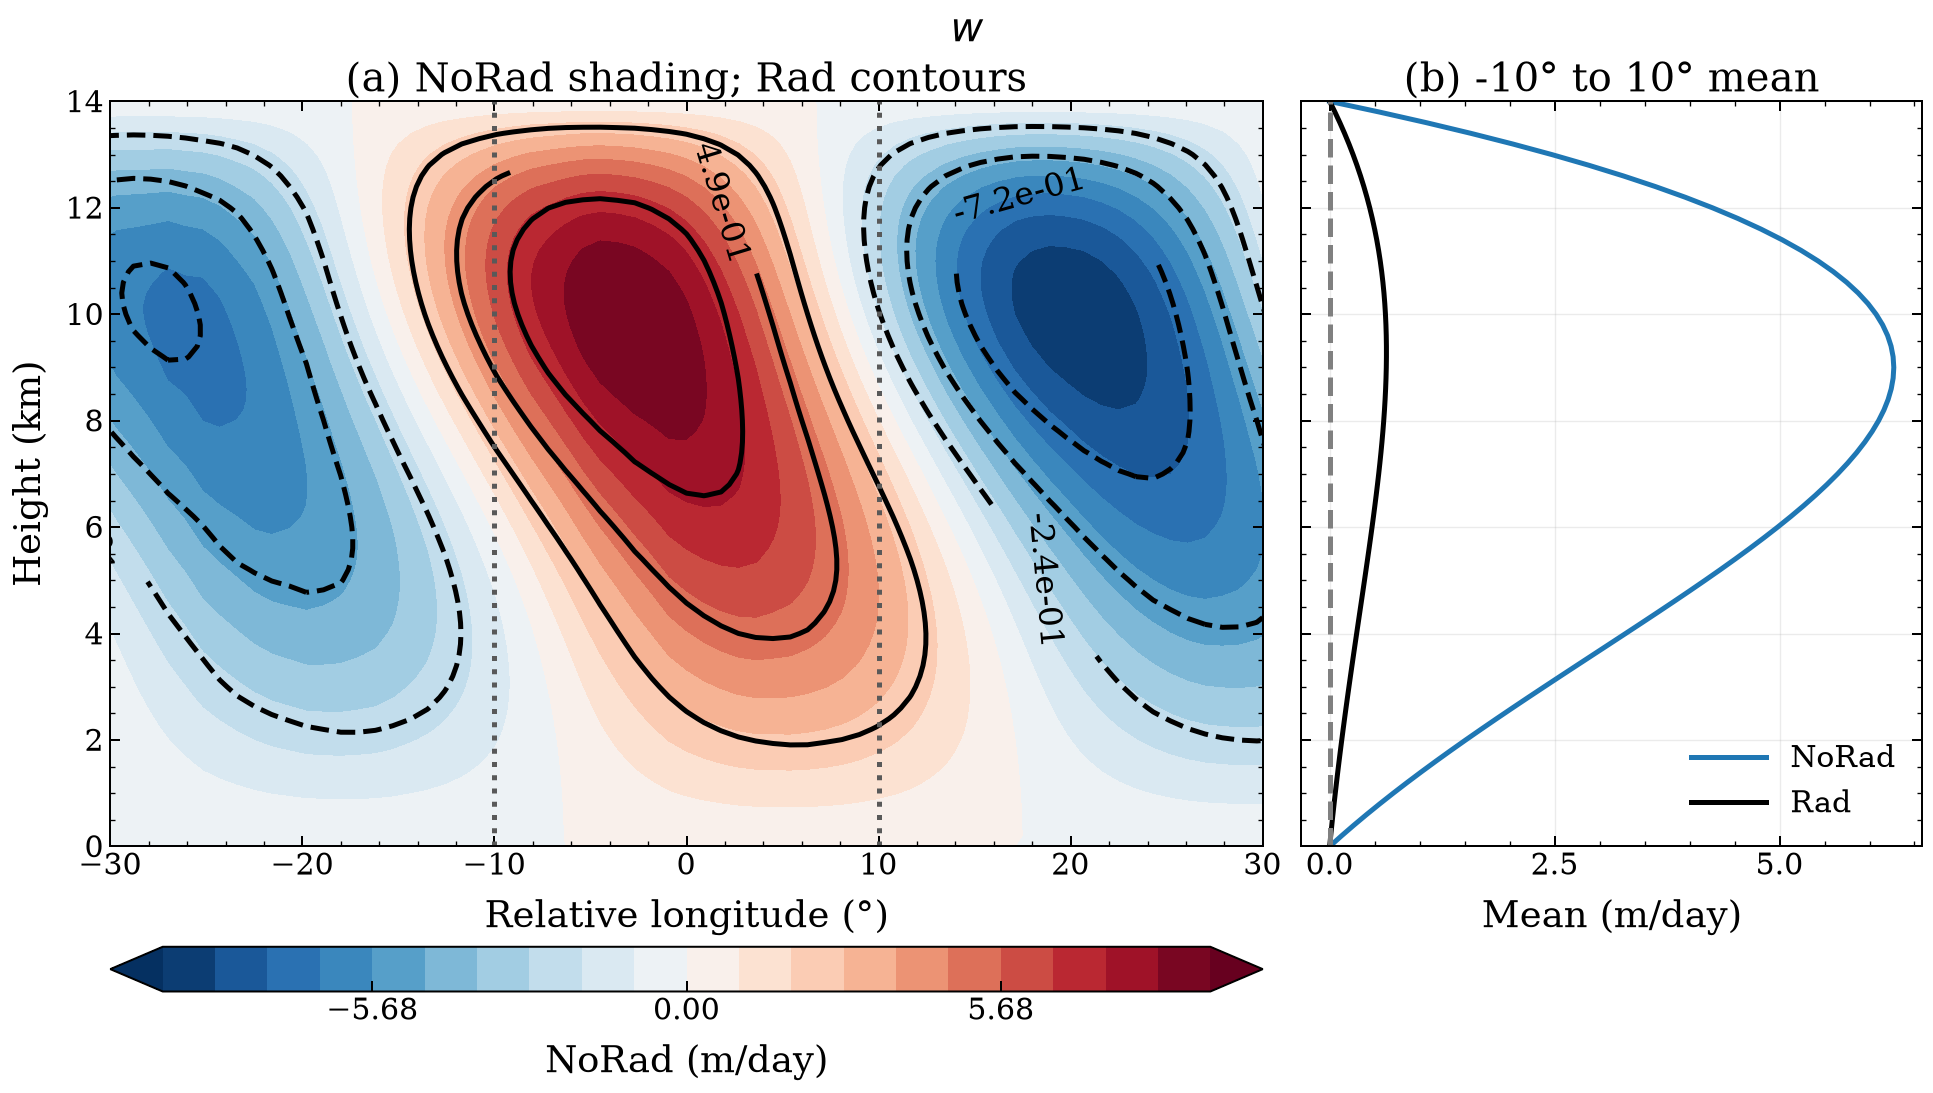

Saved w: slides, manuscript


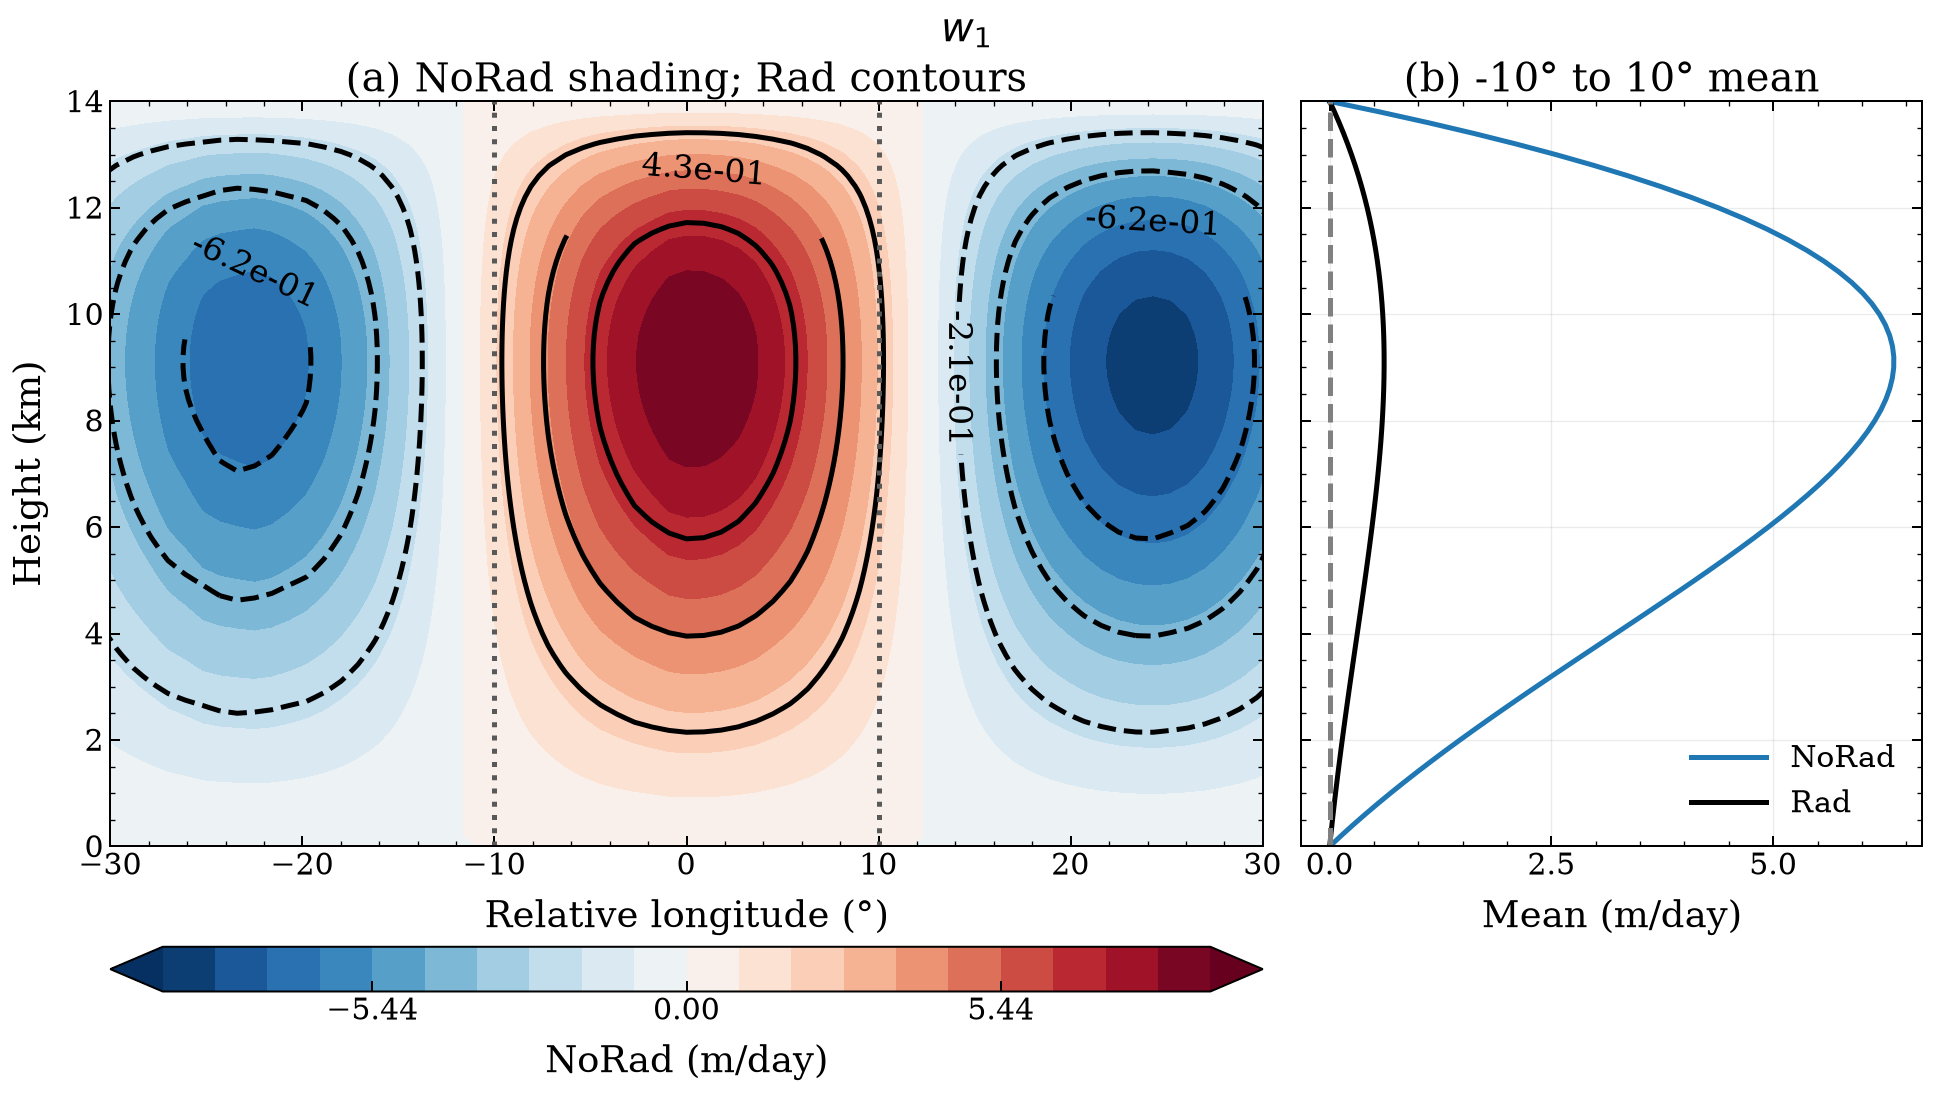

Saved w1: slides, manuscript


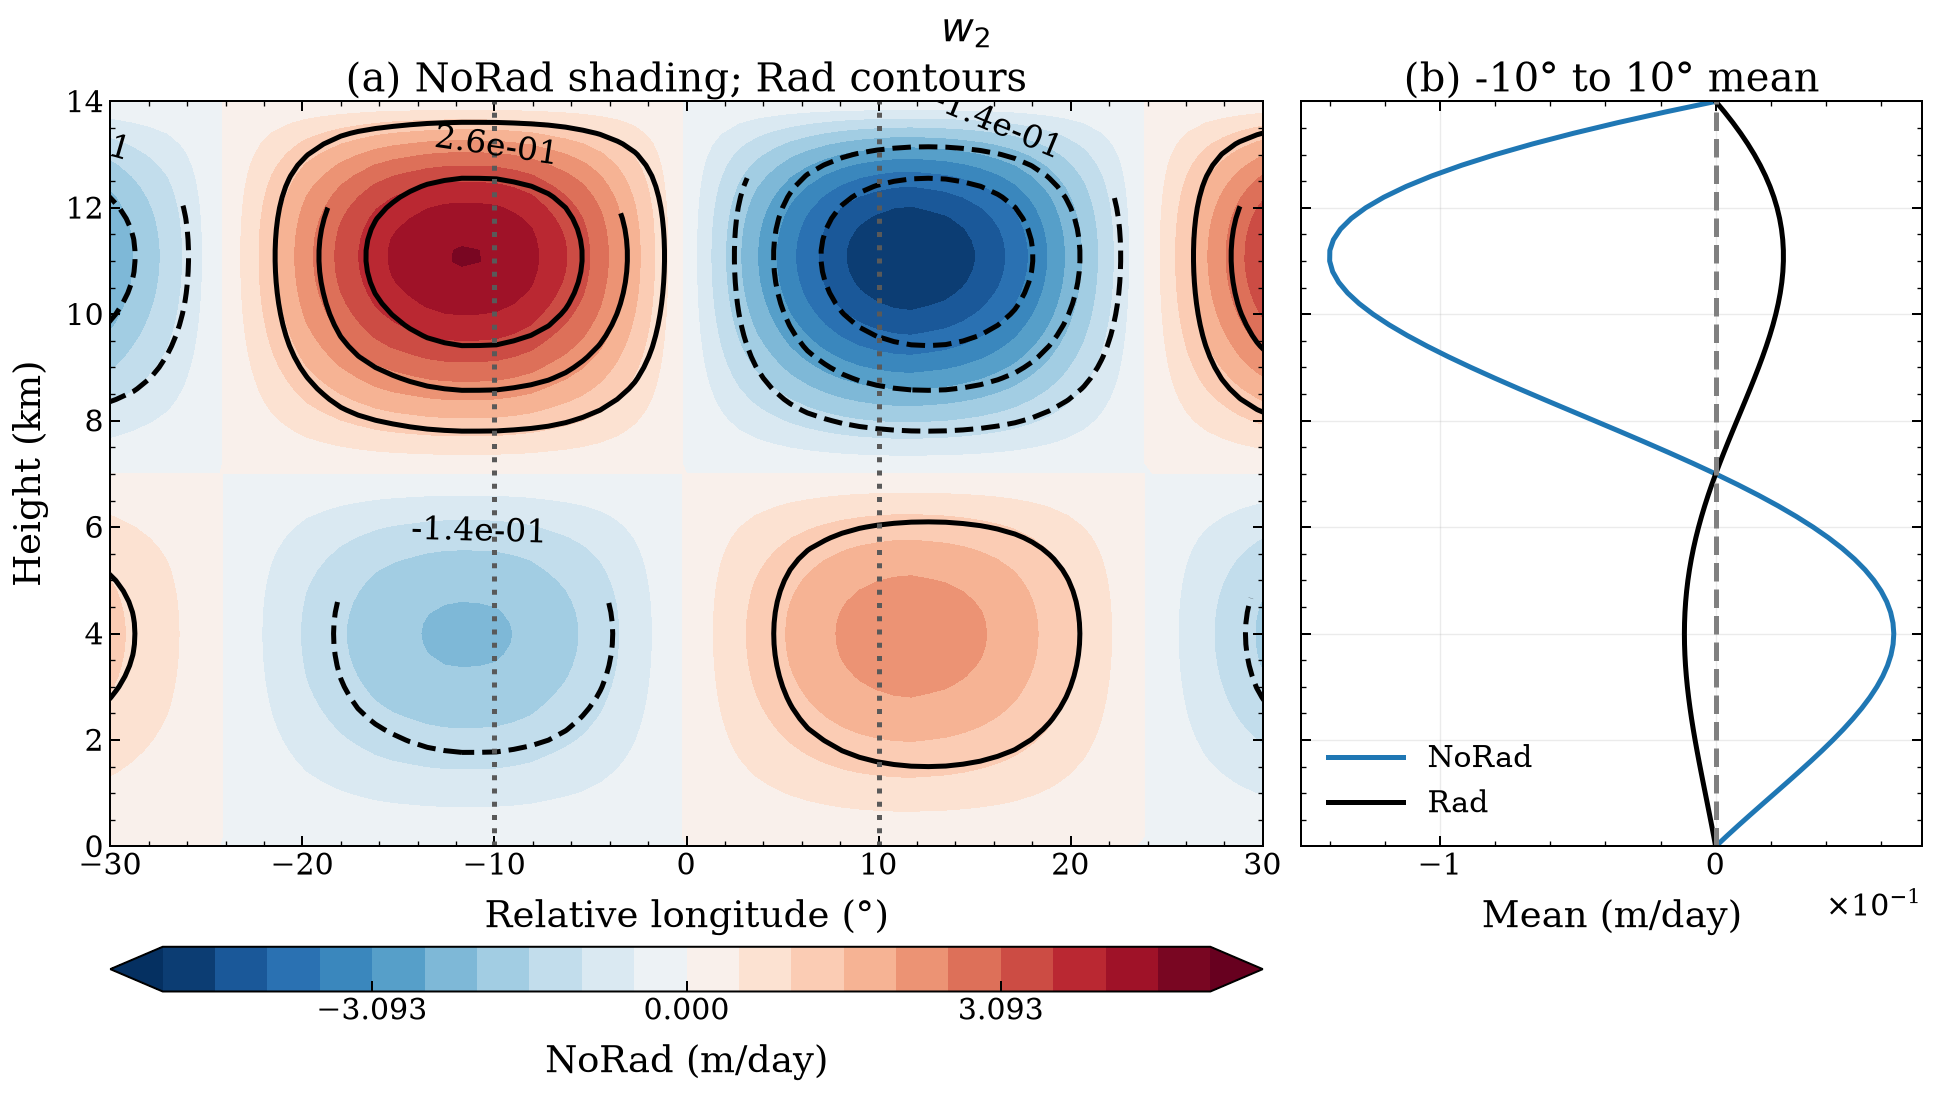

Saved w2: slides, manuscript


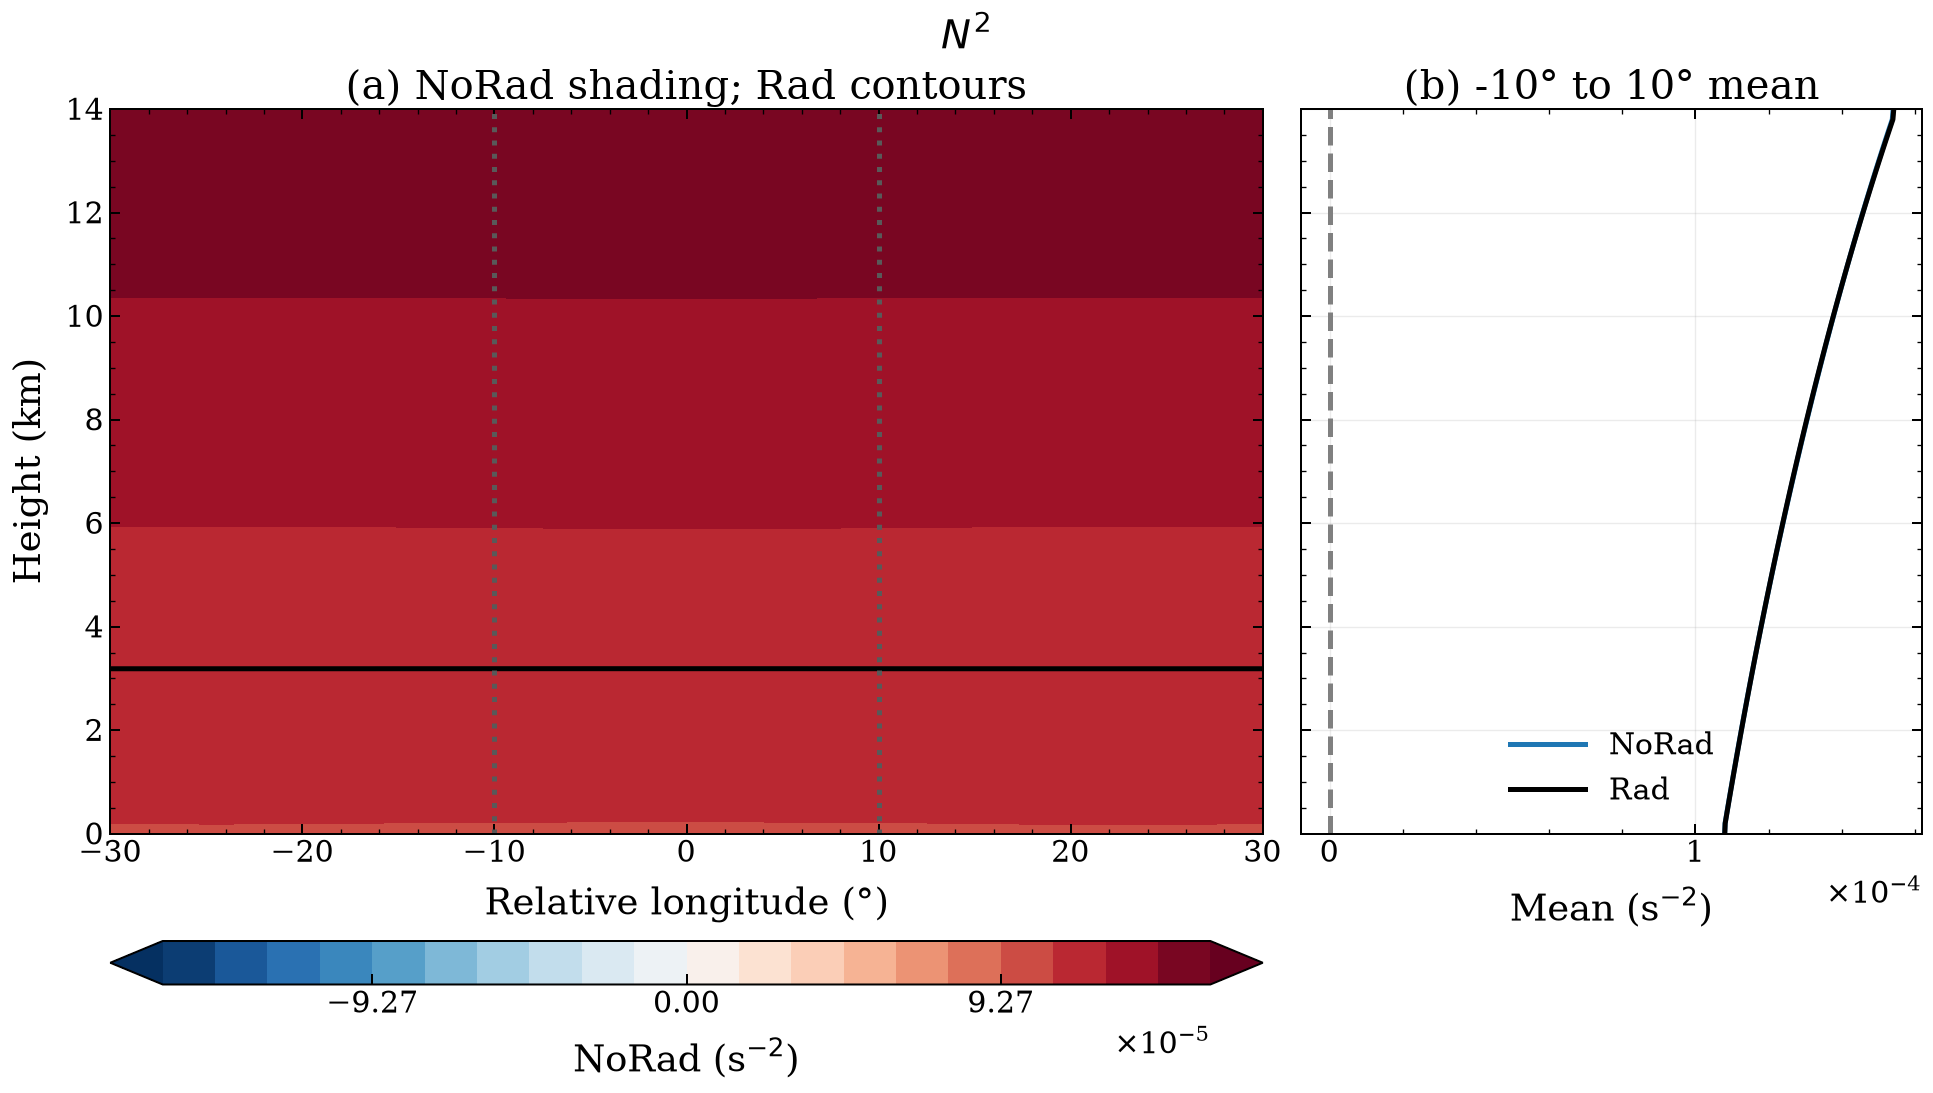

Saved N2: slides, manuscript


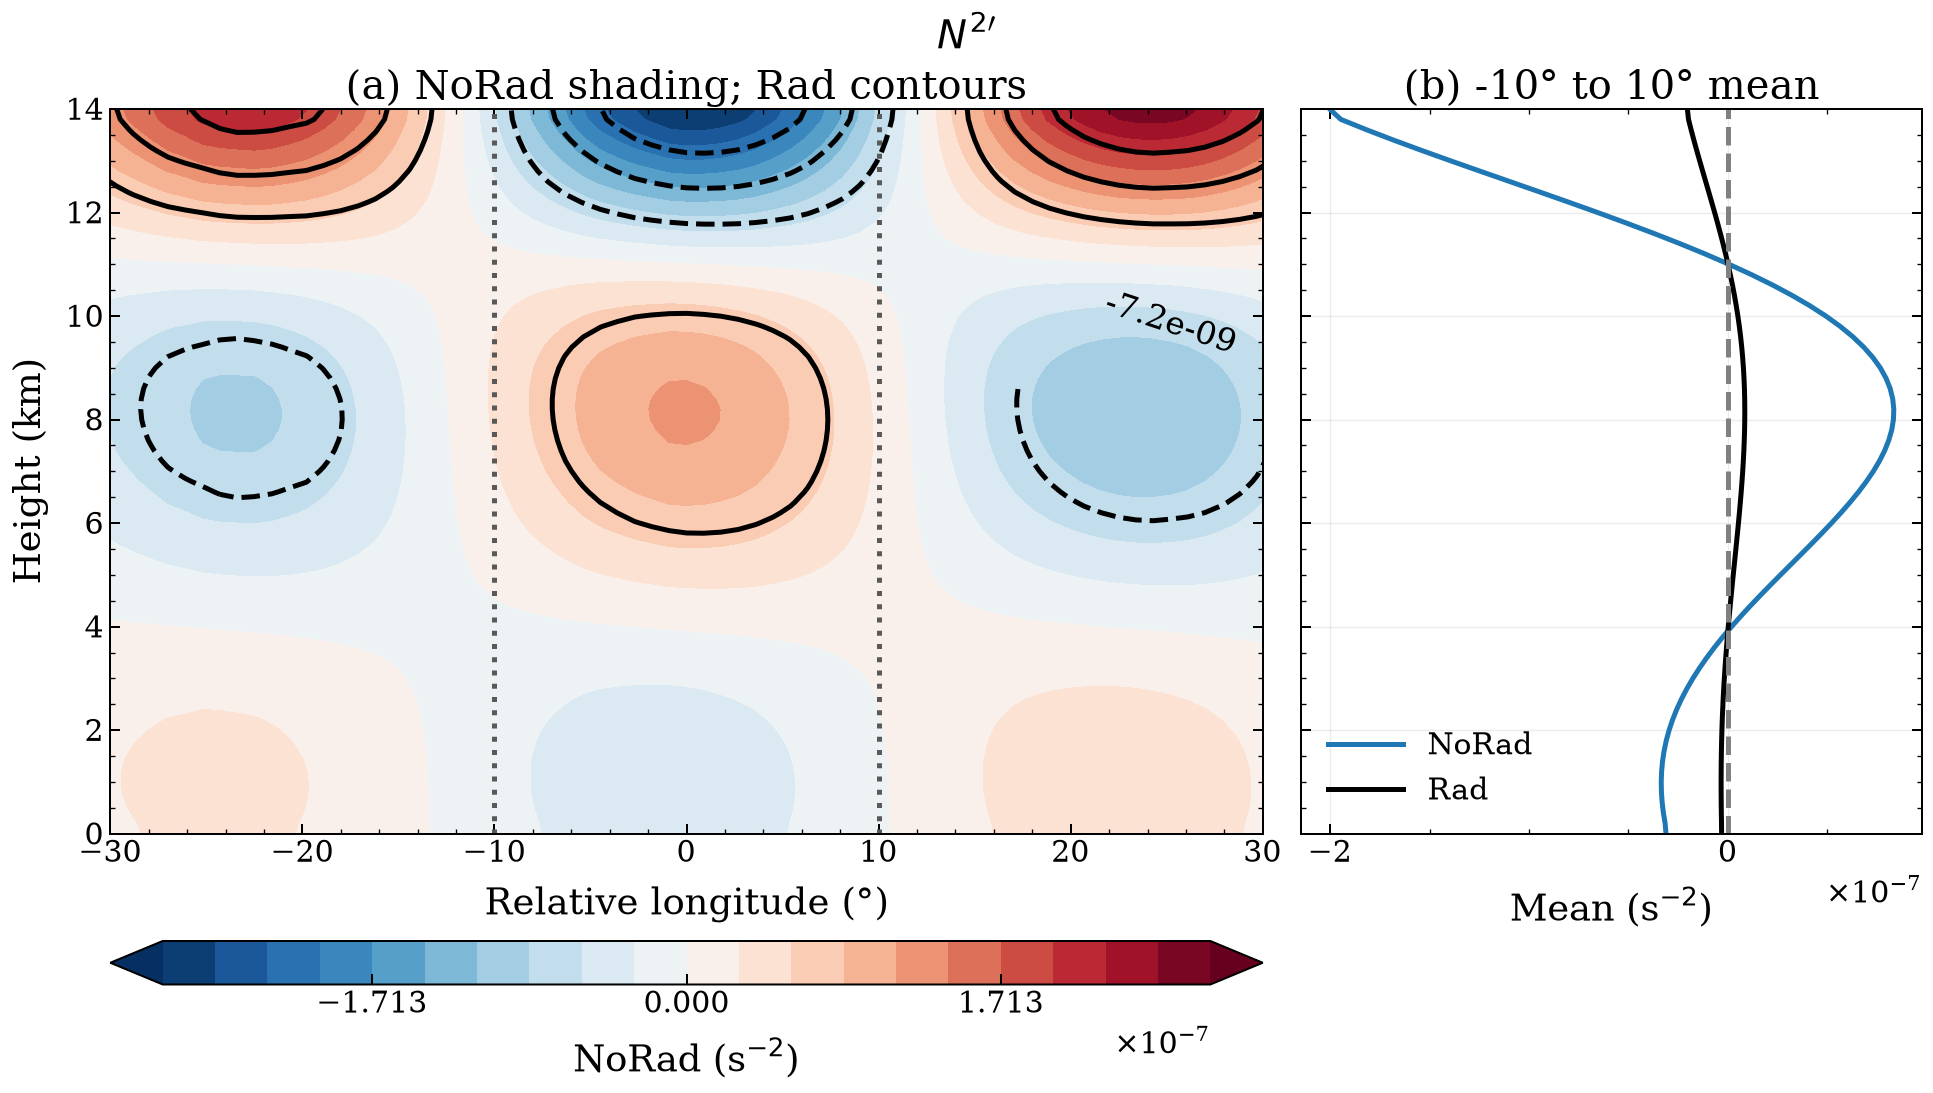

Saved N2_anom: slides, manuscript


In [6]:
comparison_profiles = {}
comparison_exports = {}

for variable, (label, units) in comparison_variables.items():
    comparison_exports[variable] = {}
    for style_name in export_styles:
        style = figure_styles[style_name]
        figure, profiles = plot_experiment_comparison(
            variable, label, units, display_longitude_bounds, mean_longitude_bounds,
            style_name,
        )
        comparison_profiles[variable] = profiles
        style_dir = comparison_figure_dir / style_name
        style_dir.mkdir(parents=True, exist_ok=True)
        paths = []
        # Disable tight cropping so slide pixels and manuscript page width stay exact.
        with plt.rc_context({**style["rc"], "savefig.bbox": None}):
            for extension in style["formats"]:
                filename = style_dir / f"NoRad_Rad_{variable}.{extension}"
                figure.savefig(filename, dpi=style["dpi"], format=extension)
                paths.append(filename)
            if style_name == plot_style:
                plt.show()
        comparison_exports[variable][style_name] = paths
        plt.close(figure)
    print(f"Saved {variable}: {', '.join(export_styles)}")
